# Compare occupancy models

**Run all cells.** Each model sees the same six camera images per frame and predicts which
3D spaces contain objects, road, vegetation or free space. We compare those predictions with
real **Occ3D-nuScenes validation labels**, then show accuracy, speed and matching examples.

Start Docker Desktop first. The isolated model runtime and 100 camera frames are prepared locally.
Your regular notebook Python environment and environment variables stay unchanged.

## 1. Choose models and sample count

M0 and M1 are two sizes of **FlashOCC**, not two different model families. **GaussianOcc** is a
different family, trained with self-supervision. Their training data supervision and input
resolutions differ, so this compares the released systems, not architecture alone.

OccFormer's original nuScenes checkpoint targets LiDAR segmentation; it is excluded rather
than scored as an incompatible Occ3D model. Waymo labels remain available, but these pretrained
nuScenes runners do not support Waymo.

In [32]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'notebooks/_support').is_dir())
sys.path.insert(0, str(ROOT / 'notebooks/_support'))
import occupancy
import occupancy_inference as inference
from common import save_run, comparison_plot

MAX_SAMPLES = 100      # Up to the number of prepared camera frames.
DATASET = 'occ3d_nuscenes'  # Waymo: 'occ3d_waymo' with RUN_MODELS=False for labels/exports only.
EXAMPLES = 3
SEED = 42
RUN_MODELS = True      # False: view previously generated predictions only.
REFRESH = False        # True: replace cached predictions and remeasure speed.
MODELS = inference.MODELS

display(pd.DataFrame(MODELS)[['name', 'description']])

,name,description
0,FlashOCC M0,Supervised ResNet-50; 128-channel BEV/head and...
1,FlashOCC M1,Same backbone and camera resolution; 256-chann...
2,GaussianOcc,Self-supervised occupancy with Gaussian render...


## 2. Load matching images and labels

The prepared manifest matches original nuScenes camera/calibration records to Occ3D frame IDs.
All frames come from official validation scenes. This 100-frame sample is a preliminary comparison;
it does not establish full-dataset performance. See [setup and architecture](../docs/occupancy-comparison.md)
to prepare more frames or recreate the runtime.

In [33]:
samples = (inference.prepared_samples(ROOT, MAX_SAMPLES) if DATASET == 'occ3d_nuscenes'
           else occupancy.load_samples(ROOT, MAX_SAMPLES, SEED, DATASET))
display(pd.DataFrame([{'frame': s['id']} for s in samples[:5]]))

Same 100 held-out frames, six calibrated camera images each.


,frame
0,scene-0967/bc8ddffb55a642f9b809342e7f35cce6
1,scene-0102/e26feac8d43d4eed9a11e739b0d4264b
2,scene-0016/3414bbcff961455ea6549ba1a2bb3b81
3,scene-0552/bffcf51dadb047a5b6d1d377709ba188
4,scene-0519/ae12ab1abde641cbb62e5d9f75182b42


## 3. Run and evaluate each model

Each runner loads its checkpoint, warms up, predicts a 200 × 200 × 16 grid and saves the result.
The **same evaluation function** compares each prediction with visible labeled voxels.

- **mIoU ↑**: average overlap for occupied semantic classes; higher is better.
- **Occupied recall ↑**: fraction of labeled occupied space detected; low recall means missed space.
- **Occupied precision ↑**: fraction of predicted occupied space that is actually occupied.
- **Mean / p95 milliseconds ↓**: warmed, synchronized model latency for one six-camera frame.

Timing excludes image decoding/resizing, downloads, model loading, file saving and app/network
overhead. GaussianOcc timing excludes image rendering, which is not needed for occupancy logits.
Runs are sequential. A failed model prints its actual error, never a fabricated score.

In [34]:
rows = []
for model in MODELS:
    print(f"\n{model['name']}: {model['description']}")
    try:
        if RUN_MODELS:
            inference.run_model(ROOT, model, samples, refresh=REFRESH)
        row = occupancy.evaluate_model(ROOT, model, samples)
    except Exception as error:
        row = {'model': model['name'], 'status': 'error', 'reason': str(error)}
    rows.append(row)
    display(pd.DataFrame([row]))

results = save_run(ROOT, f'occupancy/{DATASET}', samples,
                   {'dataset': DATASET, 'split': 'val', 'seed': SEED,
                    'hardware': 'RTX 2070', 'precision': 'FP32',
                    'timing': 'prepared GPU inputs through occupancy output'}, rows)


FlashOCC M0: Supervised ResNet-50; 128-channel BEV/head and 1 m depth bins.
Same 100 held-out frames, six calibrated camera images each.
Running FlashOCC M0; detailed output: reports\occupancy\flashocc_m0-runner.log
FlashOCC M0: predictions ready.


,model,description,frames,predictions_found,mean_ms,p95_ms,images_per_second,status,mIoU,occupied_precision,occupied_recall,free_space_recall,visible_voxels,timing_source
0,FlashOCC M0,Supervised ResNet-50; 128-channel BEV/head and...,100,100,107.703907,118.008202,9.284714,ok,0.325561,0.771715,0.803484,0.933503,9163144,exported runner timings; compare only matching...



FlashOCC M1: Same backbone and camera resolution; 256-channel BEV/head, 0.5 m depth bins.
Same 100 held-out frames, six calibrated camera images each.
Running FlashOCC M1; detailed output: reports\occupancy\flashocc_m1-runner.log
FlashOCC M1: predictions ready.


,model,description,frames,predictions_found,mean_ms,p95_ms,images_per_second,status,mIoU,occupied_precision,occupied_recall,free_space_recall,visible_voxels,timing_source
0,FlashOCC M1,Same backbone and camera resolution; 256-chann...,100,100,147.351726,155.169343,6.786483,ok,0.333767,0.788935,0.80136,0.94002,9163144,exported runner timings; compare only matching...



GaussianOcc: Self-supervised occupancy with Gaussian rendering during training; ResNet-101.
Same 100 held-out frames, six calibrated camera images each.
Running GaussianOcc; detailed output: reports\occupancy\gaussianocc-runner.log
GaussianOcc: predictions ready.


,model,description,frames,predictions_found,mean_ms,p95_ms,images_per_second,status,mIoU,occupied_precision,occupied_recall,free_space_recall,visible_voxels,timing_source
0,GaussianOcc,Self-supervised occupancy with Gaussian render...,100,100,2595.820038,2707.87706,0.385235,ok,0.101985,0.40902,0.801663,0.675941,9163144,exported runner timings; compare only matching...


## 4. Read the comparison

Accuracy values are fractions: **0.30 mIoU = 30%**. The speed unit is a complete six-camera
frame, not one image. An `error` or `needs_inference` row has no valid comparison result.

,model,status,frames,mIoU,occupied_precision,occupied_recall,free_space_recall,mean_ms,p95_ms
0,FlashOCC M0,ok,100,0.326,0.772,0.803,0.934,107.704,118.008
1,FlashOCC M1,ok,100,0.334,0.789,0.801,0.940,147.352,155.169
2,GaussianOcc,ok,100,0.102,0.409,0.802,0.676,2595.820,2707.877


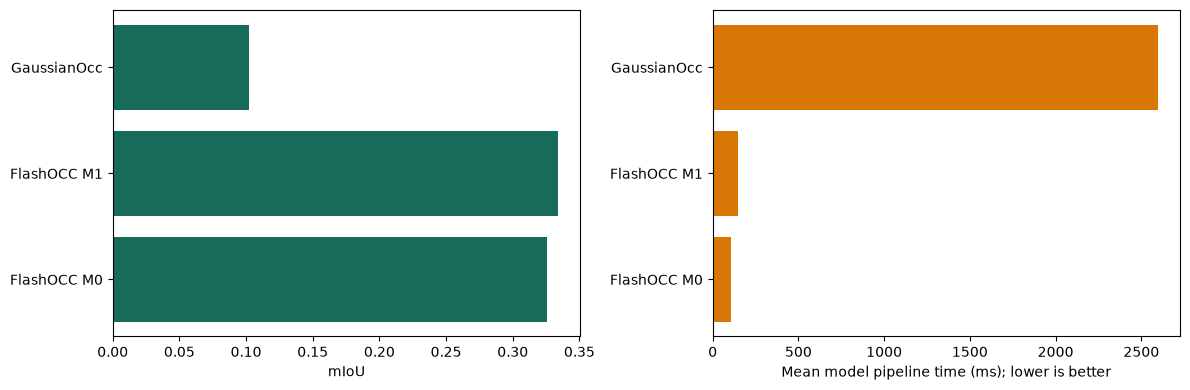

In [35]:
columns = ['model', 'status', 'frames', 'mIoU', 'occupied_precision',
           'occupied_recall', 'free_space_recall', 'mean_ms', 'p95_ms']
display(results.reindex(columns=columns).round(3))
comparison_plot(results, 'mIoU')

## 5. See the same examples side by side

Each row shows the labeled scene and each available model prediction at 0.8 m above the ego
origin. Colors identify classes; grey areas are excluded by the visibility mask. Metrics use
the whole labeled 3D volume, not just this slice.

In [36]:
occupancy.show_examples(ROOT, MODELS, samples, EXAMPLES, SEED, show_inputs=True)

TypeError: show_examples() got an unexpected keyword argument 'show_inputs'

## What these results mean for driving assistance

These tests check scene reconstruction and compute cost. They **do not establish collision-warning
safety**: a useful warning system also needs obstacle-distance error, dangerous misses, false
alarms, warning lead time, temporal stability and end-to-end mobile/backend latency on held-out
driving sequences. Six calibrated surround cameras are also different from one phone camera.

Results are saved under `reports/occupancy/occ3d_nuscenes/`. Detailed setup, model differences,
timing scope and remaining limitations: [comparison guide](../docs/occupancy-comparison.md).